# Importing libraries and amazon's csv file

In [11]:
#Libraries import
from pathlib import Path

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report)

from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

In [5]:
#Load data files

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
    
raw_data_dir = project_root / "data" / "raw"
amzn = pd.read_csv(raw_data_dir / "amzn.csv", parse_dates=["Date"])

print("Amazon dataset:", amzn.shape)
display(amzn.head())

Amazon dataset: (2513, 6)


,Date,Open,High,Low,Adj_Close,Volume
0,2016-09-01,38.544998,38.602001,38.337502,38.530998,35846000
1,2016-09-02,38.705502,38.799999,38.584999,38.622002,43636000
2,2016-09-06,38.702000,39.473999,38.511002,39.443501,74396000
3,2016-09-07,39.476501,39.539501,39.216499,39.223999,48492000
4,2016-09-08,39.194500,39.325001,39.071999,39.202999,40610000


# Generating Features

In [17]:
# Function to source data from yfinance

def fetch_yclose (tickers, start, end):
    raw = yf.download( tickers=tickers, start=pd.Timestamp(start).strftime("%Y-%m-%d"),
                     end=(pd.Timestamp(end) + pd.Timedelta(days=2)).strftime("%Y-%m-%d"),
                     auto_adjust=True, progress=False, group_by="ticker", threads=True)
    if raw.empty:
        raise RuntimeError(f"No yfinance data returned for {tickers}")

    if isinstance(raw.columns, pd.MultiIndex):
        
        #yfinance can return either (Price, Ticker) or (Ticker, Price)
        if "Close" in raw.columns.get_level_values(-1):
            close=raw.xs("Close", axis=1, level=1)
        elif "Close" in raw.columns.get_level_features(0):
            close=raw.xs("Close", axis=1, level=0)
        else:
            raise KeyError("Could not locate Close")
        if isinstance(close, pd.Series):
            close= close.to_frame(name=tickers[0])
            
    else: 
        close=raw[["Close"]].rename(columns={"Close": tickers[0]})

    close.index = pd.to_datetime(close.index).tz_localize(None)
    return close.sort_index()

In [134]:
#Engineering features for market ( SPY and VIX )

market_start = amzn["Date"].min()
market_end = amzn["Date"].max()

#Use fetch function to get closing data for SPY and VIX
spy_close = fetch_yclose(["SPY"], market_start, market_end).rename(columns={"SPY":"SPY_Close"})
vix_close = fetch_yclose(["^VIX"], market_start, market_end)
vix_close.columns = ["VIX"]

#Join SPY and VIX data by date
market = spy_close.join(vix_close, how="outer").sort_index()
market.index.name = "Date"

#SPY log return
market["SPY_LogRet_1d"] = np.log(market["SPY_Close"] / market["SPY_Close"].shift(1))
for h in [5, 21, 63]:
    market[f"SPY_LogRet_{h}d"] = np.log(market["SPY_Close"]/market["SPY_Close"].shift(h))

#Other SPY reaftures
market["SPY_Volatility_20d"] = market["SPY_LogRet_1d"].rolling(20,min_periods=20).std() * np.sqrt(252)
market["SPY_SMA50"] = market["SPY_Close"] / market["SPY_Close"].rolling(50, min_periods=50).mean()

#VIX features
market["VIX_Change_1d"] = market["VIX"].diff(1)
market["VIX_Change_5d"] = market["VIX"].diff(5)

In [136]:
print("SPY/VIX:", market.index.min().date(), "to", market.index.max().date(), market.shape)
display(market.head())

SPY/VIX: 2016-09-01 to 2026-09-02 (2515, 10)


,SPY_Close,VIX,SPY_LogRet_1d,SPY_LogRet_5d,SPY_LogRet_21d,SPY_LogRet_63d,SPY_Volatility_20d,SPY_SMA50,VIX_Change_1d,VIX_Change_5d
Date,,,,,,,,,,
2016-09-01,184.717010,13.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-09-02,185.549713,11.98,0.004498,NaN,NaN,NaN,NaN,NaN,-1.500000,NaN
2016-09-06,186.110474,12.02,0.003018,NaN,NaN,NaN,NaN,NaN,0.040001,NaN
2016-09-07,186.093491,11.94,-0.000091,NaN,NaN,NaN,NaN,NaN,-0.080001,NaN
2016-09-08,185.668655,12.51,-0.002286,NaN,NaN,NaN,NaN,NaN,0.570001,NaN


In [138]:
(market.isna().sum()/len(market))*100

SPY_Close             0.039761
VIX                   0.000000
SPY_LogRet_1d         0.119284
SPY_LogRet_5d         0.278330
SPY_LogRet_21d        0.914513
SPY_LogRet_63d        2.584493
SPY_Volatility_20d    1.630219
SPY_SMA50             3.936382
VIX_Change_1d         0.039761
VIX_Change_5d         0.198807
dtype: float64

In [39]:
#Function to get Treasury yield data from FRED
def fetch_fred(start, end):
    series = ["DGS10", "DGS2", "DGS3MO"]

    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + ",".join(series)
    fred = pd.read_csv(url)
    date_col = fred.columns[0]
    fred = fred.rename(columns={date_col: "Date"})
    fred["Date"] = pd.to_datetime(fred["Date"], errors="coerce")
    
    for c in series:
        fred[c] = pd.to_numeric(fred[c].replace(",", np.nan), errors="coerce")
        fred = fred.dropna(subset=["Date"]).set_index("Date").sort_index()
        fred = fred.loc[pd.Timestamp(start):pd.Timestamp(end)]
    
        if not fred[series].notna().any().any():
            raise ValueError("FRED graph csv returned no usable data")
        return fred[series]

In [41]:
#Generating the yield features
yields = fetch_fred(market_start, market_end)
yields.index = pd.to_datetime(yields.index)
yields.index.name = "Date"
yields["10Y_2Y_Spread"] = yields["DGS10"] - yields["DGS2"]
yields["10Y_Change_1d"] = yields["DGS10"].diff(1)
yields["10Y_Change_5d"] = yields["DGS10"].diff(5)

In [53]:
print("FRED:", yields.index.min().date(), "to", yields.index.max().date(), yields.shape)
display(yields.head())

FRED: 2016-09-01 to 2026-09-01 (2609, 6)


,DGS10,DGS2,DGS3MO,10Y_2Y_Spread,10Y_Change_1d,10Y_Change_5d
Date,,,,,,
2016-09-01,1.57,0.78,0.33,0.79,NaN,NaN
2016-09-02,1.60,0.80,0.33,0.80,0.03,NaN
2016-09-05,NaN,NaN,NaN,NaN,NaN,NaN
2016-09-06,1.55,0.74,0.32,0.81,NaN,NaN
2016-09-07,1.54,0.74,0.34,0.80,-0.01,NaN


In [71]:
(yields.isna().sum()/len(market))*100

DGS10            4.373757
DGS2             4.373757
DGS3MO           4.373757
10Y_2Y_Spread    4.373757
10Y_Change_1d    8.787276
10Y_Change_5d    8.548708
dtype: float64

In [115]:
# Functions to make some technical indicators

def rsi_wilder(close, period=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100/ (1 +rs))
    #handle uninterrupted rises/falls sensibly
    rsi = rsi.where(avg_loss.ne(0), 100)
    rsi = rsi.where(avg_gain.ne(0) | avg_loss.ne(0), 50)
    return rsi
    
def adx_wilder(high, low, close, period=14):
    up_move = high.diff()
    down_move = -low.diff()
    plus_dm = up_move.where((up_move > down_move) & (up_move > 0), 0.0)
    minus_dm = down_move.where((down_move > up_move) & (down_move > 0), 0.0)
    prev_close = close.shift(1)
    tr = pd.concat([high - low, (high - prev_close).abs(),
                   (low - prev_close).abs()], axis=1).max(axis=1)
    atr = tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    plus_di = 100 * plus_dm.ewm(alpha=1/period, min_periods=period, adjust=False).mean()/atr
    minus_di = 100 * minus_dm.ewm(alpha=1/period, min_periods=period, adjust=False).mean()/atr
    dx = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di).replace(0,np.nan)
    return dx.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

def rolling_slope_normalized(series, window=10, normalizer=None):
    x = np.arange(window, dtype=float)
    x = x - x.mean()
    denom = (x**2).sum()

    def slope( y):
        if np.isnan(y).any():
            return np.nan
        return float((x * (y-y.mean())).sum() / denom)

    slopes = series.rolling(window, min_periods=window).apply(slope, raw=True)
    if normalizer is not None:
        slopes = slopes / normalizer.replace(0, np.nan)
    return slopes 

In [123]:
#Function to add new features 
def add_stock_features(g):
    g = g.sort_values("Date").copy()
    close = g["Adj_Close"]
    volume = g["Volume"]
    logret1 = np.log(close / close.shift(1))

    for h in [1, 5, 21, 63]: # for multiple horizons' log returns
        g[f"Log_Return_{h}d"] = np.log(close / close.shift(h))

    for w in [20, 50, 200]: #for multiple price/sma periods
        g[f"Price_SMA{w}"] = close / close.rolling(w, min_periods=w).mean()

    g["RSI14"] = rsi_wilder(close, 14)
    g["ADX14"] = adx_wilder(g["High"], g["Low"], close, 14)
    
    #to make rolling volatility
    for w in [10, 60]:
        g[f"Rolling_Volatility_{w}d"] = logret1.rolling(w, min_periods=w).mean()

    for w in [20, 60]: #to make relative volume changes
        g[f"Relative_Volume_{w}d"] = volume / volume.rolling(w, min_periods=w).mean()

    #to make bollinger %b
    sma20 = close.rolling(20, min_periods=20).mean()
    sd20 = close.rolling(20, min_periods=20).std()
    upper = sma20 + 2 * sd20
    lower = sma20 -2 * sd20
    g["Bollinger_PctB"] = (close - lower) / (upper -lower).replace(0, np.nan)

    #to make obv slope
    signed_volume = np.sign(close.diff()).fillna(0) * volume
    g["OBV"] = signed_volume.cumsum()
    avg_volume20 = volume.rolling(20, min_periods=20).mean()
    g["OBV_Slope_10d"] = rolling_slope_normalized(g["OBV"], 10, avg_volume20)    

    return g

In [128]:
#make the features, iterate by ticker so ticker/date columns are preserved
stock_features = add_stock_features(amzn).sort_values(["Date"]).reset_index(drop=True)

print("Feature panel shape:", stock_features.shape)
display(stock_features[[
    "Date", "Log_Return_1d", "Price_SMA20", "RSI14",
    "ADX14", "Rolling_Volatility_10d", "Relative_Volume_20d",
    "Bollinger_PctB", "OBV_Slope_10d"]].head())

Feature panel shape: (2513, 22)


,Date,Log_Return_1d,Price_SMA20,RSI14,ADX14,Rolling_Volatility_10d,Relative_Volume_20d,Bollinger_PctB,OBV_Slope_10d
0,2016-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-09-02,0.002359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-09-06,0.021047,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-09-07,-0.005581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-09-08,-0.000536,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [130]:
(stock_features.isna().sum()/len(market))*100

Date                      0.000000
Open                      0.000000
High                      0.000000
Low                       0.000000
Adj_Close                 0.000000
Volume                    0.000000
Log_Return_1d             0.039761
Log_Return_5d             0.198807
Log_Return_21d            0.834990
Log_Return_63d            2.504970
Price_SMA20               0.755467
Price_SMA50               1.948310
Price_SMA200              7.912525
RSI14                     0.556660
ADX14                     1.033797
Rolling_Volatility_10d    0.397614
Rolling_Volatility_60d    2.385686
Relative_Volume_20d       0.755467
Relative_Volume_60d       2.345924
Bollinger_PctB            0.755467
OBV                       0.000000
OBV_Slope_10d             0.755467
dtype: float64

In [140]:
#Join SPY/VIX features on date
market_feature_cols = ["SPY_LogRet_1d", "SPY_LogRet_5d", "SPY_LogRet_21d", "SPY_LogRet_63d",
    "SPY_Volatility_20d", "SPY_SMA50", "VIX", "VIX_Change_1d", "VIX_Change_5d"]

panel = stock_features.merge(market[market_feature_cols].reset_index(),on="Date", 
                             how="left", validate="many_to_one")

In [148]:
panel.head()

,Date,Open,High,Low,Adj_Close,Volume,Log_Return_1d,Log_Return_5d,Log_Return_21d,Log_Return_63d,Price_SMA20,Price_SMA50,Price_SMA200,RSI14,ADX14,Rolling_Volatility_10d,Rolling_Volatility_60d,Relative_Volume_20d,Relative_Volume_60d,Bollinger_PctB,OBV,OBV_Slope_10d,SPY_LogRet_1d,SPY_LogRet_5d,SPY_LogRet_21d,SPY_LogRet_63d,SPY_Volatility_20d,SPY_SMA50,VIX,VIX_Change_1d,VIX_Change_5d
0,2016-09-01,38.544998,38.602001,38.337502,38.530998,35846000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.48,NaN,NaN
1,2016-09-02,38.705502,38.799999,38.584999,38.622002,43636000,0.002359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43636000.0,NaN,0.004498,NaN,NaN,NaN,NaN,NaN,11.98,-1.500000,NaN
2,2016-09-06,38.702000,39.473999,38.511002,39.443501,74396000,0.021047,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,118032000.0,NaN,0.003018,NaN,NaN,NaN,NaN,NaN,12.02,0.040001,NaN
3,2016-09-07,39.476501,39.539501,39.216499,39.223999,48492000,-0.005581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69540000.0,NaN,-0.000091,NaN,NaN,NaN,NaN,NaN,11.94,-0.080001,NaN
4,2016-09-08,39.194500,39.325001,39.071999,39.202999,40610000,-0.000536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28930000.0,NaN,-0.002286,NaN,NaN,NaN,NaN,NaN,12.51,0.570001,NaN


In [162]:
#Make stock relative return to SPY and rolling beta 
panel = panel.sort_values(["Date"]).reset_index(drop=True)
for h in [1, 5, 21, 63]:
    panel[f"Relative_Return_{h}d"] = panel[f"Log_Return_{h}d"] - panel[f"SPY_LogRet_{h}d"]

# calculate rolling beta against SPY using daily log returns
panel = panel.sort_values("Date").copy()

stock_ret = panel["Log_Return_1d"]
spy_ret = panel["SPY_LogRet_1d"]

for w in [20, 60]: 
    cov = stock_ret.rolling(w, min_periods=w).cov(spy_ret)
    var = spy_ret.rolling(w, min_periods=w).var()
    
    panel[f"Rolling_Beta_SPY_{w}d"] = cov / var.replace(0, np.nan)

In [164]:
(panel.isna().sum()/len(market))*100

Date                      0.000000
Open                      0.000000
High                      0.000000
Low                       0.000000
Adj_Close                 0.000000
Volume                    0.000000
Log_Return_1d             0.039761
Log_Return_5d             0.198807
Log_Return_21d            0.834990
Log_Return_63d            2.504970
Price_SMA20               0.755467
Price_SMA50               1.948310
Price_SMA200              7.912525
RSI14                     0.556660
ADX14                     1.033797
Rolling_Volatility_10d    0.397614
Rolling_Volatility_60d    2.385686
Relative_Volume_20d       0.755467
Relative_Volume_60d       2.345924
Bollinger_PctB            0.755467
OBV                       0.000000
OBV_Slope_10d             0.755467
SPY_LogRet_1d             0.079523
SPY_LogRet_5d             0.238569
SPY_LogRet_21d            0.874751
SPY_LogRet_63d            2.544732
SPY_Volatility_20d        1.590457
SPY_SMA50                 3.896620
VIX                 

In [166]:
#Align FRED data to our date, lag 1 row
#use forward fill for missing data for date differences
trading_dates = pd.DatetimeIndex(sorted(panel["Date"].dropna().unique()), name="Date")
fred_aligned = yields.reindex(trading_dates).ffill()
fred_feature_cols =["DGS10", "10Y_Change_1d", "10Y_Change_5d", "10Y_2Y_Spread", "DGS3MO"]
fred_aligned = fred_aligned[fred_feature_cols].shift(1)
fred_aligned = fred_aligned.rename(columns={
    "DGS10": "Treasury_10Y_Yield",
    "DGS3MO": "Treasury_3M_Yield"})
panel = panel.merge(fred_aligned.reset_index(), on="Date", how="left", validate="many_to_one")
panel = panel.rename(columns={
    "10Y_Change_1d": "Treasury_10Y_Change_1d",
    "10Y_Change_5d": "Treasury_10Y_Change_5d",
    "10Y_2Y_Spread": "Treasury_10Y_2Y_Spread"})

In [172]:
print("Panel with technical, market and macro features:", panel.shape)
display(panel[[
    "Date", "SPY_LogRet_1d", "Relative_Return_1d",
    "Rolling_Beta_SPY_20d", "Treasury_10Y_Yield",
    "Treasury_10Y_2Y_Spread", "VIX"]].head())

Panel with technical, market and macro features: (2513, 42)


,Date,SPY_LogRet_1d,Relative_Return_1d,Rolling_Beta_SPY_20d,Treasury_10Y_Yield,Treasury_10Y_2Y_Spread,VIX
0,2016-09-01,NaN,NaN,NaN,NaN,NaN,13.48
1,2016-09-02,0.004498,-0.002139,NaN,1.57,0.79,11.98
2,2016-09-06,0.003018,0.018030,NaN,1.60,0.80,12.02
3,2016-09-07,-0.000091,-0.005489,NaN,1.55,0.81,11.94
4,2016-09-08,-0.002286,0.001750,NaN,1.54,0.80,12.51


In [174]:
(panel.isna().sum()/len(market))*100

Date                      0.000000
Open                      0.000000
High                      0.000000
Low                       0.000000
Adj_Close                 0.000000
Volume                    0.000000
Log_Return_1d             0.039761
Log_Return_5d             0.198807
Log_Return_21d            0.834990
Log_Return_63d            2.504970
Price_SMA20               0.755467
Price_SMA50               1.948310
Price_SMA200              7.912525
RSI14                     0.556660
ADX14                     1.033797
Rolling_Volatility_10d    0.397614
Rolling_Volatility_60d    2.385686
Relative_Volume_20d       0.755467
Relative_Volume_60d       2.345924
Bollinger_PctB            0.755467
OBV                       0.000000
OBV_Slope_10d             0.755467
SPY_LogRet_1d             0.079523
SPY_LogRet_5d             0.238569
SPY_LogRet_21d            0.874751
SPY_LogRet_63d            2.544732
SPY_Volatility_20d        1.590457
SPY_SMA50                 3.896620
VIX                 

In [218]:
#Function to make Black Scholes synthetic features 
from scipy.stats import norm

def bs_atm_call_features(spot, sigma_annual, rate_decimal, days_to_expiry):
    S = pd.to_numeric(spot, errors="coerce").astype(float)
    sigma = pd.to_numeric(sigma_annual, errors="coerce").astype(float)
    r = pd.to_numeric(rate_decimal, errors="coerce").astype(float)
    T = float(days_to_expiry) / 365.0
    valid = (S > 0) & (sigma > 0) & r.notna()
    d1 = pd.Series(np.nan, index=S.index, dtype=float)
    d2 = pd.Series(np.nan, index=S.index, dtype=float)
    d1.loc[valid] = ( np.log(S.loc[valid] / S.loc[valid]) + (r.loc[valid] 
                    + 0.5 * sigma.loc[valid] ** 2) * T) / (sigma.loc[valid] * np.sqrt(T))
    d2.loc[valid] = d1.loc[valid] - sigma.loc[valid] * np.sqrt(T)
    delta = pd.Series(np.nan, index=S.index, dtype=float)
    delta.loc[valid] = norm.cdf(d1.loc[valid])
    call_price = pd.Series(np.nan, index=S.index, dtype=float)
    call_price.loc[valid] = ( S.loc[valid] * norm.cdf(d1.loc[valid]) - S.loc[valid]
                            * np.exp(-r.loc[valid] * T) * norm.cdf(d2.loc[valid]) )
    return delta, call_price, call_price / S

In [208]:
#Creating BS features 

#a dedicated 20-day estimate of realized volatility 
panel["Rolling_Volatility_20d"] = (panel["Log_Return_1d"].transform(
    lambda s: s.rolling(20, min_periods=20).std() * np.sqrt(252)) )

#Risk free interest rate taken from treasury yield
rate_decimal = panel["Treasury_3M_Yield"] / 100

for days in [30, 60]:
    delta, call_price, call_pct = bs_atm_call_features( panel["Adj_Close"],
                            panel["Rolling_Volatility_20d"], rate_decimal, days)
    panel[f"BS_Delta_ATM_{days}d"] = delta
    panel[f"BS_Call_Price_ATM_{days}d"] = call_price
    panel[f"BS_Call_Price_ATM_%Spot_{days}d"] = call_pct

In [210]:
#Target creation 

horizons = [1, 5, 21, 63]

for h in horizons:
    future_close = panel["Adj_Close"].shift(-h)
    panel[f"fwd_ret_{h}d"] = np.log(future_close / panel["Adj_Close"])
    panel[f"direction_{h}d"] = np.where( future_close.notna(), 
                                       (panel[f"fwd_ret_{h}d"] > 0).astype(float), np.nan)
    panel[f"label_end_{h}d"] = panel["Date"].shift(-h)

display(panel[[ f"direction_{h}d" for h in horizons]].apply(pd.Series.value_counts).T)

,1.0,0.0
direction_1d,1331,1181
direction_5d,1406,1102
direction_21d,1580,912
direction_63d,1611,839


In [215]:
#Saving feature layers into csvs into another folder to reuse later

raw = ["Open", "High", "Low", "Adj_Close", "Volume"]

technical = [*[f"Log_Return_{h}d" for h in horizons],
                  "Price_SMA20", "Price_SMA50", "Price_SMA200", "RSI14", "ADX14",
                  "Rolling_Volatility_10d", "Rolling_Volatility_60d",
                  "Relative_Volume_20d", "Relative_Volume_60d",
                  "Bollinger_PctB", "OBV_Slope_10d"]

market = [*[f"SPY_LogRet_{h}d" for h in horizons],"SPY_Volatility_20d", "SPY_SMA50",
               *[f"Relative_Return_{h}d" for h in horizons], 
                "Rolling_Beta_SPY_20d", "Rolling_Beta_SPY_60d"]

macro = ["Treasury_10Y_Yield", "Treasury_10Y_Change_1d", "Treasury_10Y_Change_5d", 
              "Treasury_10Y_2Y_Spread", "Treasury_3M_Yield", "VIX", 
              "VIX_Change_1d", "VIX_Change_5d"]

BS = ["BS_Delta_ATM_30d", "BS_Call_Price_ATM_%Spot_30d", 
           "BS_Delta_ATM_60d", "BS_Call_Price_ATM_%Spot_60d"]

layer_feat = {"raw" : raw,
              "technical" : raw + technical,
              "market" : raw + technical + market,
              "macro" : raw + technical + market + macro,
              "bs" : raw + technical + market + macro + BS}

key_n_target = ["Date", "Adj_Close", 
                *[f"fwd_ret_{h}d" for h in horizons],
                *[f"direction_{h}d" for h in horizons],
                *[f"label_end_{h}d" for h in horizons] ]

saved_layer_paths = {}

for layer_name, feat_cols in layer_feat.items():
    cols = list(dict.fromkeys(key_n_target + feat_cols))
    layer_df = panel[cols].copy()
    path = raw_data_dir / f"amzn_{layer_name}.csv"
    if True:
        layer_df.to_csv(path, index=False)
    saved_layer_paths[layer_name] = path
    print(f"{layer_name:14s} | {len(feat_cols):2d} predictors |"
            f"{layer_df.shape[0]:,} rows | {path.name}")

raw            |  5 predictors |2,513 rows | amzn_raw.csv
technical      | 20 predictors |2,513 rows | amzn_technical.csv
market         | 32 predictors |2,513 rows | amzn_market.csv
macro          | 40 predictors |2,513 rows | amzn_macro.csv
bs             | 44 predictors |2,513 rows | amzn_bs.csv


# New Features EDA

In [226]:
TRAIN_END = "2024-09-01"
RANDOM_STATE =42

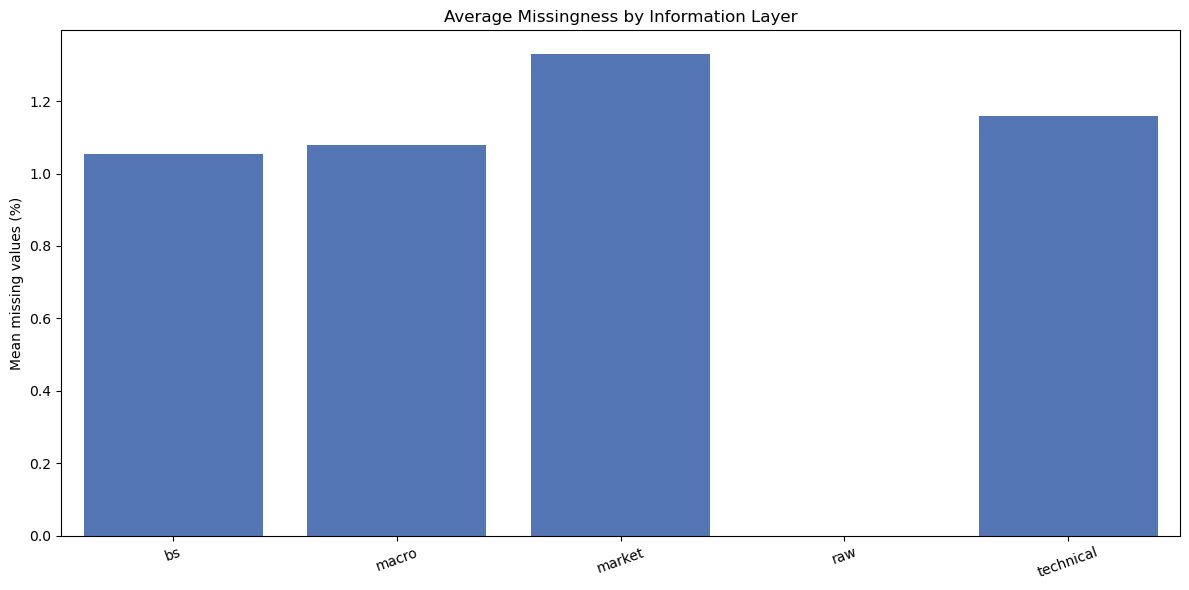

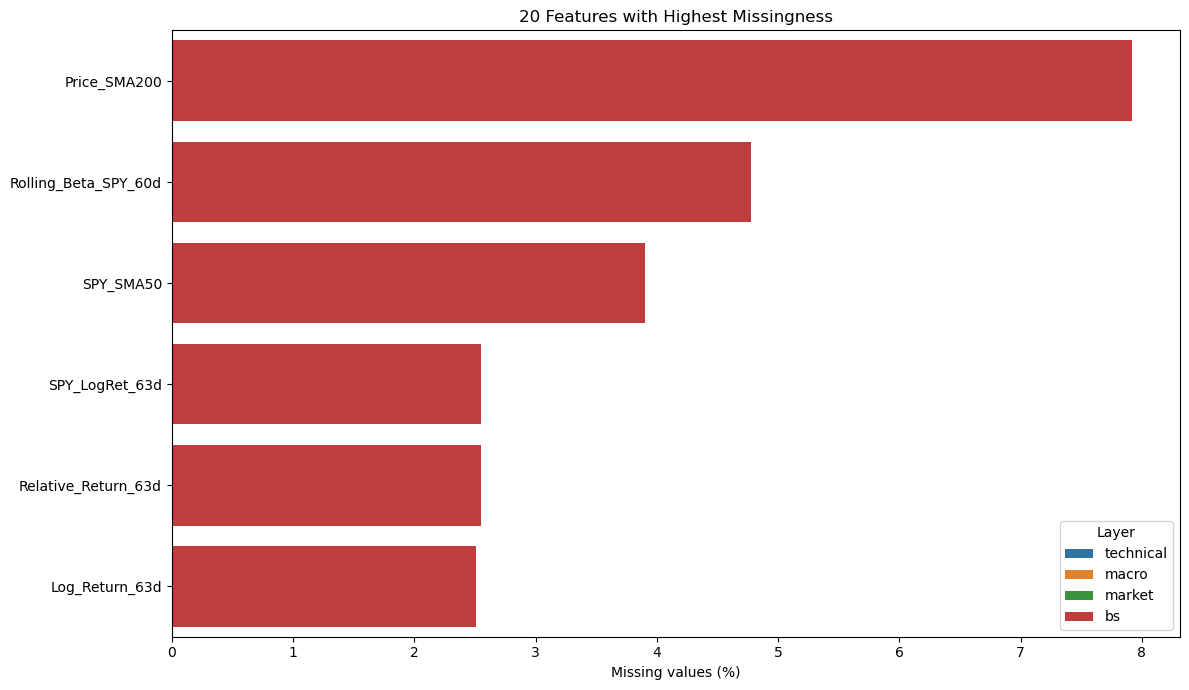

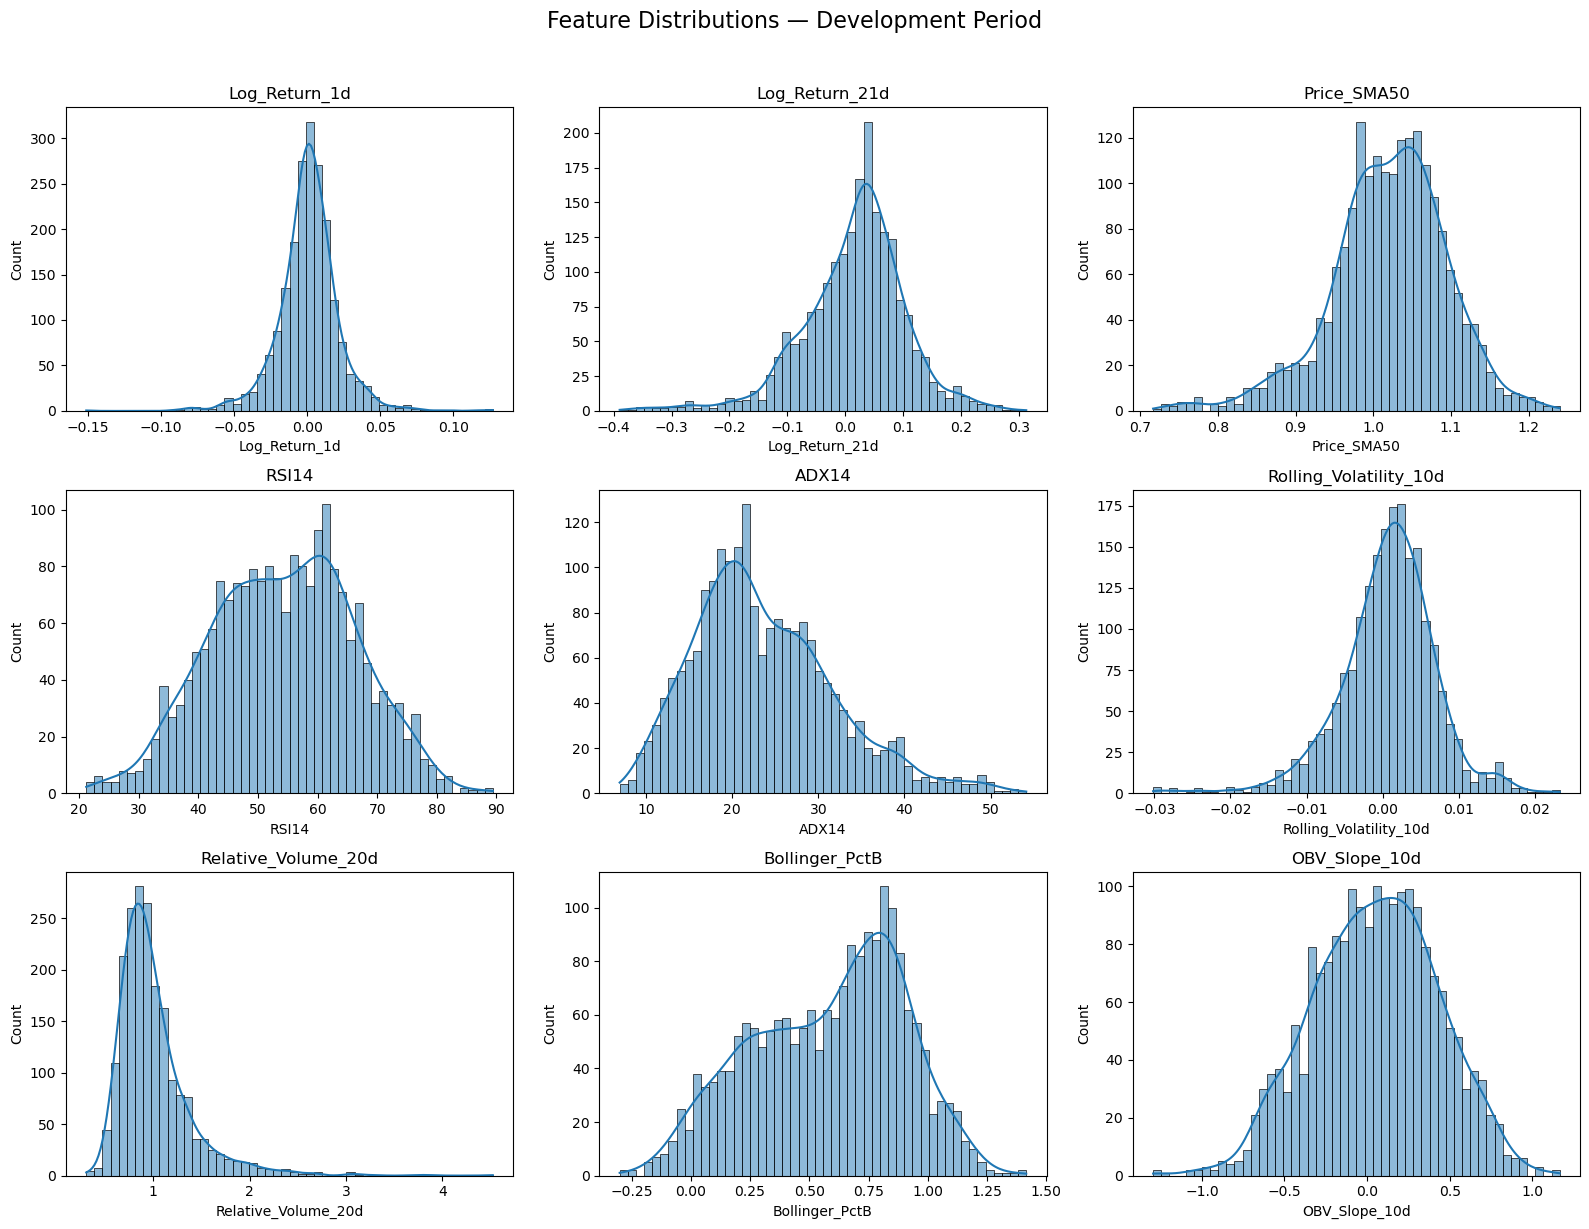

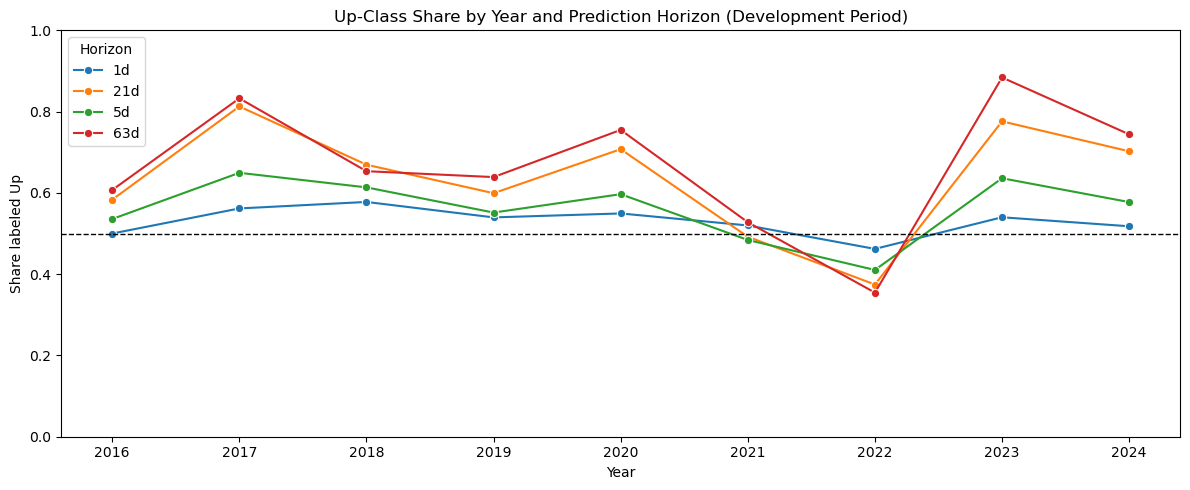

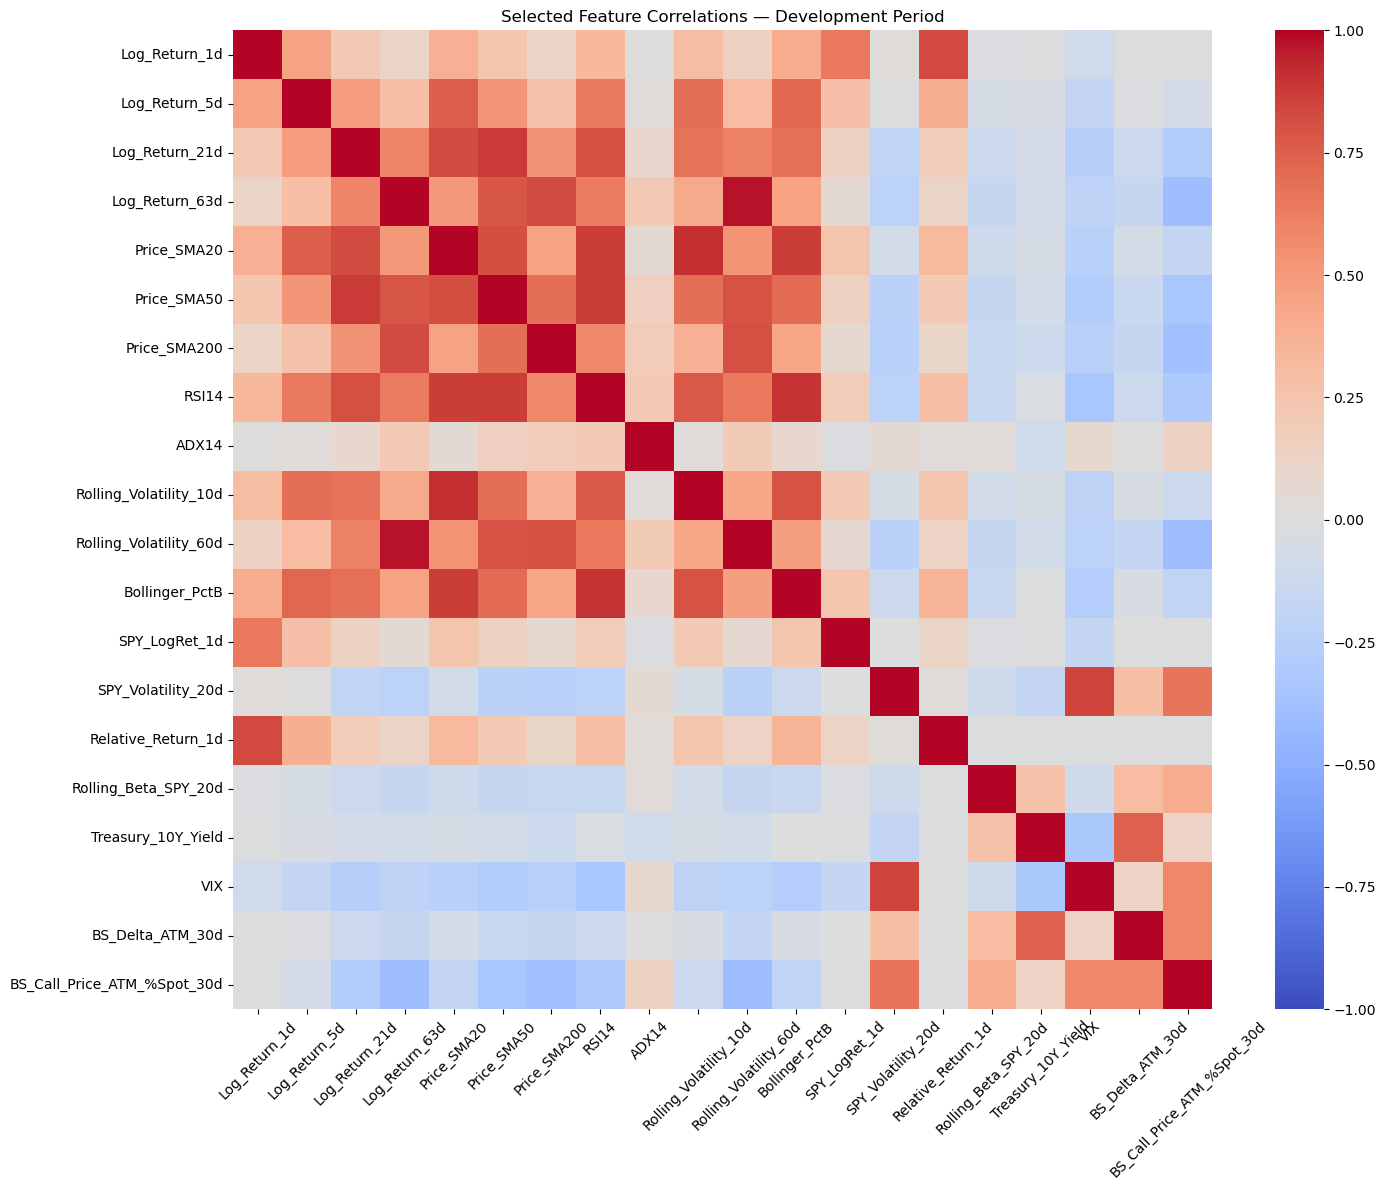

In [236]:
# Feature missingness by information layer
missing_rows = []
for layer_name, feature_cols in layer_feat.items():
    for col in feature_cols:
        missing_rows.append({
            "Layer": layer_name,
            "Feature": col,
            "Missing_Pct": panel[col].isna().mean() * 100
        })
missingness = pd.DataFrame(missing_rows)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=missingness.groupby("Layer", as_index=False)["Missing_Pct"].mean(),
    x="Layer", y="Missing_Pct", color="#4472C4"
)
plt.title("Average Missingness by Information Layer")
plt.ylabel("Mean missing values (%)")
plt.xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

top_missing = missingness.sort_values("Missing_Pct", ascending=False).head(20)
plt.figure(figsize=(12, 7))
sns.barplot(data=top_missing, y="Feature", x="Missing_Pct", hue="Layer", dodge=False)
plt.title("20 Features with Highest Missingness")
plt.xlabel("Missing values (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

# Technical indicator distributions (sample for readability)
eda_cols = [
    "Log_Return_1d", "Log_Return_21d", "Price_SMA50", "RSI14", "ADX14",
    "Rolling_Volatility_10d", "Relative_Volume_20d", "Bollinger_PctB", "OBV_Slope_10d"
]
sample_eda = panel.loc[panel["Date"] < TRAIN_END, eda_cols].sample(
    n=min(20000, panel.loc[panel["Date"] < TRAIN_END, eda_cols].dropna(how="all").shape[0]),
    random_state=RANDOM_STATE
)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, eda_cols):
    sns.histplot(sample_eda[col].dropna(), bins=50, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Count")
for ax in axes.flat[len(eda_cols):]:
    ax.axis("off")
fig.suptitle("Feature Distributions — Development Period", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# Target balance by horizon and year, development period only
target_balance = panel.loc[panel["Date"] < TRAIN_END].copy()
target_balance["Year"] = target_balance["Date"].dt.year
balance = (
    target_balance.melt(
        id_vars=["Date", "Year"],
        value_vars=[f"direction_{h}d" for h in horizons],
        var_name="Horizon", value_name="Direction"
    )
    .dropna(subset=["Direction"])
)
balance["Horizon"] = balance["Horizon"].str.extract(r"direction_(\d+)d")[0] + "d"
year_balance = balance.groupby(["Year", "Horizon"])["Direction"].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=year_balance, x="Year", y="Direction", hue="Horizon", marker="o")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1)
plt.title("Up-Class Share by Year and Prediction Horizon (Development Period)")
plt.ylabel("Share labeled Up")
plt.xlabel("Year")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Correlation heatmap on a manageable selection of representative engineered features
corr_cols = [
    "Log_Return_1d", "Log_Return_5d", "Log_Return_21d", "Log_Return_63d",
    "Price_SMA20", "Price_SMA50", "Price_SMA200", "RSI14", "ADX14",
    "Rolling_Volatility_10d", "Rolling_Volatility_60d", "Bollinger_PctB",
    "SPY_LogRet_1d", "SPY_Volatility_20d", "Relative_Return_1d",
    "Rolling_Beta_SPY_20d", "Treasury_10Y_Yield", "VIX",
    "BS_Delta_ATM_30d", "BS_Call_Price_ATM_%Spot_30d"
]
corr = panel.loc[panel["Date"] < TRAIN_END, corr_cols].corr()
plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Selected Feature Correlations — Development Period")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()